In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense

In [ ]:
# Load Fashion-MNIST Dataset

In [ ]:
train_data = pd.read_csv("fashion-mnist_train.csv")
test_data = pd.read_csv("fashion-mnist_test.csv")

print("Training Data:", train_data.shape)
print("Testing Data:", test_data.shape)

Training Data: (60000, 785)
Testing Data: (10000, 785)


In [ ]:
X_train = train_data.iloc[:, 1:].values
y_train = train_data.iloc[:, 0].values

X_test = test_data.iloc[:, 1:].values
y_test = test_data.iloc[:, 0].values

In [ ]:
# Normalize Pixel Values

In [ ]:
X_train = X_train / 255.0

X_test = X_test / 255.0

In [ ]:
X_train = X_train.reshape(-1, 28, 28)

X_test = X_test.reshape(-1, 28, 28)

In [ ]:
# Define Fashion-MNIST Class Names

In [ ]:
class_names = [
    'T-shirt',
    'Trouser',
    'Pullover',
    'Dress',
    'Coat',
    'Sandal',
    'Shirt',
    'Sneaker',
    'Bag',
    'Ankle Boot'
]

In [ ]:
# Build Feedforward Neural Network (FNN)

In [ ]:
model = Sequential([

    Flatten(input_shape=(28, 28)),

    Dense(128, activation='relu'),

    Dense(64, activation='relu'),

    Dense(10, activation='softmax')

])

model.summary()

C:\Users\Dell\anaconda3\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)                  │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compile the Model

In [ ]:
model.compile(

    optimizer='adam',

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']

)

In [ ]:
# Model Training

In [ ]:
history = model.fit(

    X_train,

    y_train,

    epochs=10,

    batch_size=128,

    validation_split=0.1

)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.8068 - loss: 0.5602 - val_accuracy: 0.8478 - val_loss: 0.4333
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.8587 - loss: 0.3995 - val_accuracy: 0.8427 - val_loss: 0.4442
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8703 - loss: 0.3625 - val_accuracy: 0.8752 - val_loss: 0.3572
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.8781 - loss: 0.3328 - val_accuracy: 0.8765 - val_loss: 0.3458
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.8851 - loss: 0.3126 - val_accuracy: 0.8772 - val_loss: 0.3486
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8911 - loss: 0.2977 - val_accuracy: 0.8840 - val_loss: 0.3260
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.8932 - loss: 0.2870 - val_accuracy: 0.8818 - val_loss: 0.3331
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.8990 - loss: 0.2718 - val_accurac

In [ ]:
# Calculate Testing Accuracy

In [ ]:
test_loss, test_accuracy = model.evaluate(
    X_test, y_test
)

print("Testing Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8875 - loss: 0.2996
Testing Accuracy: 88.7499988079071 %


In [ ]:
# Predict Five Test Images

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step


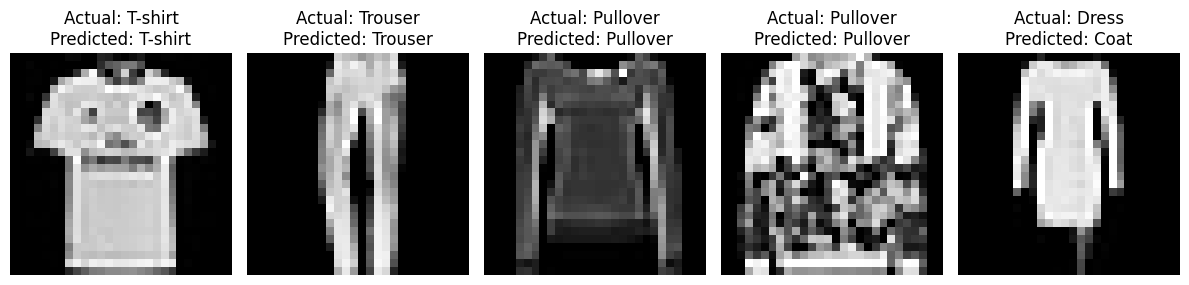

In [ ]:
predictions = model.predict(X_test[:5])

predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(12, 5))

for i in range(5):

    plt.subplot(1, 5, i + 1)

    plt.imshow(X_test[i], cmap='gray')

    actual = class_names[y_test[i]]

    predicted = class_names[predicted_labels[i]]

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}"
    )

    plt.axis('off')

plt.tight_layout()

plt.show()

In [ ]:
# Evaluate Model Using Test Data

In [ ]:
test_loss, test_accuracy = model.evaluate(
    X_test, y_test
)

print("Testing Loss:", test_loss)
print("Testing Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8875 - loss: 0.2996
Testing Loss: 0.2996062636375427
Testing Accuracy: 88.7499988079071 %


In [ ]:
# Generate Predictions for Test Dataset

In [ ]:
y_pred = model.predict(X_test)

predicted_labels = np.argmax(y_pred, axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


In [ ]:
# Generate Confusion Matrix

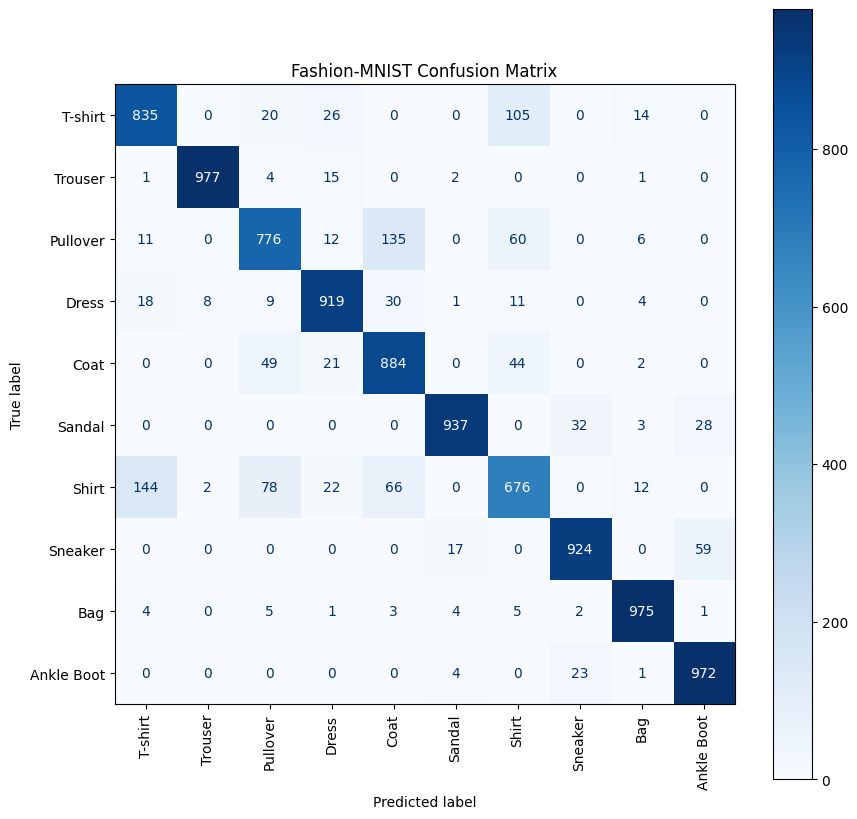

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, predicted_labels)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 10))

display.plot(
    cmap='Blues',
    ax=ax,
    xticks_rotation='vertical'
)

plt.title("Fashion-MNIST Confusion Matrix")

plt.show()

| No. | Question | Answer |
|---|---|---|
| 1 | Which function loads the Fashion-MNIST dataset? | `fashion_mnist.load_data()` |
| 2 | How many training and testing images are present? | 60,000 training and 10,000 testing images. |
| 3 | How many classes are present? | 10 classes. |
| 4 | What is the image size? | 28 × 28 pixels. |
| 5 | What does X_train contain? | Training images. |
| 6 | What does y_train contain? | Actual training labels. |
| 7 | Why do we divide images by 255? | To normalize pixel values between 0 and 1. |
| 8 | What is the purpose of Flatten()? | Converts 2D images into 1D arrays. |
| 9 | How many values are present after flattening? | 784 values (28 × 28). |
| 10 | What is Sequential()? | Creates a neural network layer by layer. |
| 11 | What does Dense(128) represent? | A fully connected layer with 128 neurons. |
| 12 | Why do we use ReLU? | It introduces non-linearity and converts negative values to zero. |
| 13 | Why do we use Dense(10)? | Because Fashion-MNIST has 10 output classes. |
| 14 | Why do we use Softmax? | To generate probabilities for all 10 classes. |
| 15 | What does model.compile() do? | Configures optimizer, loss and metrics. |
| 16 | Which optimizer is used? | Adam optimizer. |
| 17 | Which loss function is used? | Sparse Categorical Crossentropy. |
| 18 | What does model.fit() do? | Trains the model. |
| 19 | What is an epoch? | One complete pass through the training dataset. |
| 20 | What does model.evaluate() do? | Evaluates the model on test data. |
| 21 | What does model.predict() do? | Predicts clothing classes for test images. |
| 22 | What does np.argmax() do? | Finds the index of the highest probability. |
| 23 | What does plt.imshow() do? | Displays an image. |
| 24 | What does confusion_matrix(y_test, y_pred) do? | Compares actual and predicted labels. |
| 25 | What does the diagonal of a confusion matrix represent? | Correctly classified images. |